# Multiple Linear Regression

Companion notebook to the note [Multiple Linear Regression](../../notes/regression/multiple_regression.md) and the [exercises](../../exercises/regression/multiple_regression.md).

We estimate $\hat{\boldsymbol\beta}=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y$, assess fit with $R^2$, adjusted $R^2$ and the overall $F$ test, diagnose multicollinearity with VIF, and see what happens under perfect collinearity and omitted variables.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(0)
df = pd.DataFrame({'hours': [2, 3, 5, 7, 9],
                   'attendance': [70, 80, 60, 90, 95],
                   'score': [65, 70, 75, 85, 95]})
df

,hours,attendance,score
0,2,70,65
1,3,80,70
2,5,60,75
3,7,90,85
4,9,95,95


## 1. Normal equations

Build the design matrix with a column of ones and solve $\mathbf X^\top\mathbf X\hat{\boldsymbol\beta}=\mathbf X^\top\mathbf y$ directly. The values match the hand calculation in the note: $\hat y=49.182+3.786x_1+0.116x_2$.

In [2]:
X = np.column_stack([np.ones(len(df)), df['hours'], df['attendance']])
y = df['score'].values.astype(float)
XtX, Xty = X.T @ X, X.T @ y
print("X'X =\n", XtX)
print("X'y =", Xty)
beta = np.linalg.solve(XtX, Xty)
print("beta_hat =", np.round(beta, 4))

X'X =
 [[5.0000e+00 2.6000e+01 3.9500e+02]
 [2.6000e+01 1.6800e+02 2.1650e+03]
 [3.9500e+02 2.1650e+03 3.2025e+04]]
X'y = [  390.  2165. 31325.]
beta_hat = [49.1818  3.7856  0.1156]


## 2. Fit, $R^2$, adjusted $R^2$ and the $F$ test

Here $R^2=1-\mathrm{SSE}/\mathrm{SST}$, $\bar R^2=1-\frac{\mathrm{SSE}/(n-p-1)}{\mathrm{SST}/(n-1)}$ and $F=\frac{(\mathrm{SST}-\mathrm{SSE})/p}{\mathrm{SSE}/(n-p-1)}$. Note that $x_2$ is not individually significant even though the overall model is: with $n=5$ there are only 2 residual degrees of freedom.

In [3]:
n, p = len(y), 2
e = y - X @ beta
SSE = e @ e
SST = np.sum((y - y.mean())**2)
R2 = 1 - SSE / SST
adjR2 = 1 - (SSE / (n - p - 1)) / (SST / (n - 1))
F = ((SST - SSE) / p) / (SSE / (n - p - 1))
print(f"SSE={SSE:.3f}, SST={SST:.1f}, R2={R2:.4f}, adjR2={adjR2:.4f}, F={F:.1f}")

model = sm.OLS(y, X).fit()
print(model.summary().tables[1])
print("statsmodels F:", round(model.fvalue, 1), " p:", round(model.f_pvalue, 4))

SSE=1.835, SST=580.0, R2=0.9968, adjR2=0.9937, F=315.0
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         49.1818      2.954     16.649      0.004      36.472      61.892
x1             3.7856      0.227     16.661      0.004       2.808       4.763
x2             0.1156      0.045      2.544      0.126      -0.080       0.311
statsmodels F: 315.0  p: 0.0032


/tmp/claude-1000/-home-adam-my-repos-Statistics-Notes/348b9543-6167-4bef-ba53-2f12bf33edb1/scratchpad/venv/lib/python3.12/site-packages/statsmodels/regression/linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


## 3. Multicollinearity and VIF

$\mathrm{VIF}_j=1/(1-R_j^2)$ where $R_j^2$ comes from regressing $x_j$ on the other predictors. With two predictors $R_j^2=r_{x_1x_2}^2$, so $\mathrm{VIF}=1/(1-0.677^2)\approx1.85$, far below the usual cut-offs of 5 or 10.

In [4]:
Xd = sm.add_constant(df[['hours', 'attendance']])
vif = {c: variance_inflation_factor(Xd.values, i) for i, c in enumerate(Xd.columns) if c != 'const'}
r = np.corrcoef(df['hours'], df['attendance'])[0, 1]
print("VIF:", {k: round(v, 3) for k, v in vif.items()})
print(f"r = {r:.3f},  1/(1-r^2) = {1/(1-r**2):.3f}")

VIF: {'hours': np.float64(1.845), 'attendance': np.float64(1.845)}
r = 0.677,  1/(1-r^2) = 1.845


## 4. Perfect multicollinearity

If $x_2=x_1/2$ exactly, $\mathbf X$ has rank 2 with three columns, $\mathbf X^\top\mathbf X$ is singular and the coefficients are not identified: only $\gamma=\beta_1+\beta_2/2$ is. Different $(\beta_1,\beta_2)$ on the line $\beta_1+\beta_2/2=5$ give identical fitted values.

In [5]:
x1 = np.array([2, 4, 6, 8.]); x2 = x1 / 2; yy = np.array([50, 60, 70, 80.])
Xp = np.column_stack([np.ones(4), x1, x2])
print("rank:", np.linalg.matrix_rank(Xp), "of", Xp.shape[1], "columns")
print("det(X'X) =", round(np.linalg.det(Xp.T @ Xp), 6))
for b1_, b2_ in [(5, 0), (4, 2), (0, 10), (-6, 22)]:
    print((b1_, b2_), "fitted:", 40 + b1_ * x1 + b2_ * x2)
print("minimum-norm solution (pinv):", np.round(np.linalg.pinv(Xp) @ yy, 3))

rank: 2 of 3 columns
det(X'X) = 0.0
(5, 0) fitted: [50. 60. 70. 80.]
(4, 2) fitted: [50. 60. 70. 80.]
(0, 10) fitted: [50. 60. 70. 80.]
(-6, 22) fitted: [50. 60. 70. 80.]
minimum-norm solution (pinv): [40.  4.  2.]


## 5. Omitted-variable bias

When the omitted predictor is correlated with an included one, the simple-regression slope absorbs part of its effect. For the data above, $4.177=\hat\beta_1+\hat\beta_2\,S_{12}/S_{11}$. We confirm this and then show it in a simulation where the truth is known ($\beta_1=2$, $\beta_2=3$, $\mathrm{corr}(x_1,x_2)\approx0.6$).

In [6]:
x1d, x2d = df['hours'].values, df['attendance'].values
S11 = np.sum((x1d - x1d.mean())**2); S12 = np.sum((x1d - x1d.mean()) * (x2d - x2d.mean()))
simple = np.sum((x1d - x1d.mean()) * (y - y.mean())) / S11
print(f"simple slope = {simple:.3f};  b1 + b2*S12/S11 = {beta[1] + beta[2]*S12/S11:.3f}")

N = 5000
z = rng.normal(size=(N, 2))
s1 = z[:, 0]
s2 = 0.6 * z[:, 0] + 0.8 * z[:, 1]
yv = 1 + 2 * s1 + 3 * s2 + rng.normal(size=N)
full = sm.OLS(yv, sm.add_constant(np.column_stack([s1, s2]))).fit()
short = sm.OLS(yv, sm.add_constant(s1)).fit()
print("full  model slope on x1:", round(full.params[1], 3), "(truth 2)")
print("short model slope on x1:", round(short.params[1], 3), "(expected 2 + 3*0.6 = 3.8)")

simple slope = 4.177;  b1 + b2*S12/S11 = 4.177
full  model slope on x1: 1.99 (truth 2)
short model slope on x1: 3.715 (expected 2 + 3*0.6 = 3.8)


## 6. The fitted plane

A 3D view of the regression plane through the five observations.

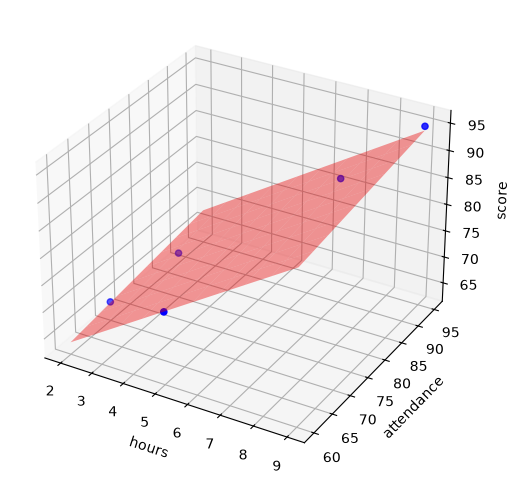

intercept: 49.182 coef: [3.7856 0.1156]


In [7]:
lr = LinearRegression().fit(df[['hours', 'attendance']], df['score'])
g1, g2 = np.meshgrid(np.linspace(2, 9, 10), np.linspace(60, 95, 10))
zz = lr.predict(pd.DataFrame({'hours': g1.ravel(), 'attendance': g2.ravel()})).reshape(g1.shape)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df['hours'], df['attendance'], df['score'], color='blue')
ax.plot_surface(g1, g2, zz, color='red', alpha=0.4)
ax.set_xlabel('hours'); ax.set_ylabel('attendance'); ax.set_zlabel('score')
plt.show()
print("intercept:", round(lr.intercept_, 3), "coef:", np.round(lr.coef_, 4))